# Overview

### Usage Profiles

This notebook visualizes four key profiles of Californian vehicle usage behavior critical for V2G assessment:

* **Daily Charger (26%):** Drivers who consistently charge their vehicles every night after daily usage, maintaining a relatively high average State of Charge (SOC).

* **Public Charger (19%):** Drivers who use their vehicle frequently but lack home charging access, relying primarily public charging and opting for fast charging.

* **BEV 2nd Vehicle (17%):** Drivers who drive considerably less frequently, potentially using the BEV as a secondary vehicle, and charge when the SOC hits a lower threshold.

* **Threshold Charger (38%):** Drivers who use their BEVs daily but charge only when necessary rather than every day.



### File Access

Example 10-year synthetic usage data for these four key profiles are stored at:

`./data/synthetic_vehicle_usage/{usage_profile}.parquet`

> 
> **Note on Confidentiality:** These profiles are **synthetic constructs**. They are generated from the average values of each cluster’s behavioral features; individual vehicle usage data is not displayed to ensure driver confidentiality.
> 

## Libraries and Setup

In [1]:
# Standard libraries
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt
import matplotlib.dates as mdates


# Add repository root to system path to allow local imports
repo_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)



# Import V2G Strategy
from src.v2g_strategy import *

##  Define Profiles and Inspect Example Data

In [2]:
#list of usage profile names
vehicle_usage_behavior_list = [
    'daily_charger',
    'public_charger', 
    'bev_second_vehicle', 
    'threshold_charger'
]

# Load and inspect an example dataset (Daily Charger)
example_profile = 'daily_charger'
example_df = pd.read_parquet(f'../data/synthetic_vehicle_usage/{example_profile}.parquet')

# Display data
example_df

,Time (s),C-rate,SOC,timestamp
0,0.000000e+00,0.000000,0.750000,2024-01-01 00:00:00.000000000
1,1.000000e+00,0.000000,0.750000,2024-01-01 00:00:01.000000000
2,2.520000e+04,0.000000,0.750000,2024-01-01 07:00:00.000000000
3,2.520100e+04,-0.000000,0.750000,2024-01-01 07:00:01.000000000
4,2.520200e+04,-0.000000,0.750000,2024-01-01 07:00:02.000000000
...,...,...,...,...
15266348,3.153434e+08,0.135211,0.841401,2033-12-28 19:24:02.669011330
15266349,3.153441e+08,0.135211,0.866682,2033-12-28 19:35:15.764584251
15266350,3.153448e+08,0.135211,0.891962,2033-12-28 19:46:28.860157171
15266351,3.153448e+08,0.000000,0.891962,2033-12-28 19:46:29.860157171


## Generate Visualizations (Figure 2)

In [6]:

def make_drive_cycle_figure_example_month ( vehicle_usage_behavior_df , vehicle_usage_behavior_title):
    
    start_date = pd.Timestamp('2024-01-01')
    end_date   = pd.Timestamp('2024-01-31')

    filtered_df = vehicle_usage_behavior_df[
        (vehicle_usage_behavior_df['timestamp'] >= start_date) &
        (vehicle_usage_behavior_df['timestamp'] < end_date)
    ]


    fig, (ax_C_rate, ax_SOC) = plt.subplots(2, 1, figsize=(6, 6), sharex=True, dpi=300)
    fig.suptitle(vehicle_usage_behavior_title, fontsize=20, fontweight='bold')
 
    ax_C_rate.plot(filtered_df['timestamp'], filtered_df ['C-rate'], color='dodgerblue', lw=2)


    ax_C_rate.set_ylim([-0.3, 1.8])
    ax_C_rate.set_ylabel('C-rate', fontsize=18)
    ax_C_rate.grid(True, linestyle='--', alpha=0.6)
    ax_SOC.grid(True, linestyle='--', alpha=0.6)




    ax_SOC.plot(filtered_df ['timestamp'], filtered_df ['SOC']*100, color='seagreen', lw=2)


    ax_SOC.set_ylabel('SOC (%)', fontsize=18)
    ax_SOC.set_ylim([0, 100])
    # Format x-axis to show day only
    ax_SOC.xaxis.set_major_formatter(mdates.DateFormatter('%d'))
    ax_SOC.set_xlabel('Day of the Month', fontsize=18)
    
    # --- Tick labels ---
    ax_C_rate.tick_params(axis='both', which='major', labelsize=15)
    ax_SOC.tick_params(axis='both', which='major', labelsize=15)



    # Improve layout
    fig.tight_layout(pad = 1)


    return fig



Generating plot for: daily_charger
Generating plot for: public_charger
Generating plot for: bev_second_vehicle
Generating plot for: threshold_charger


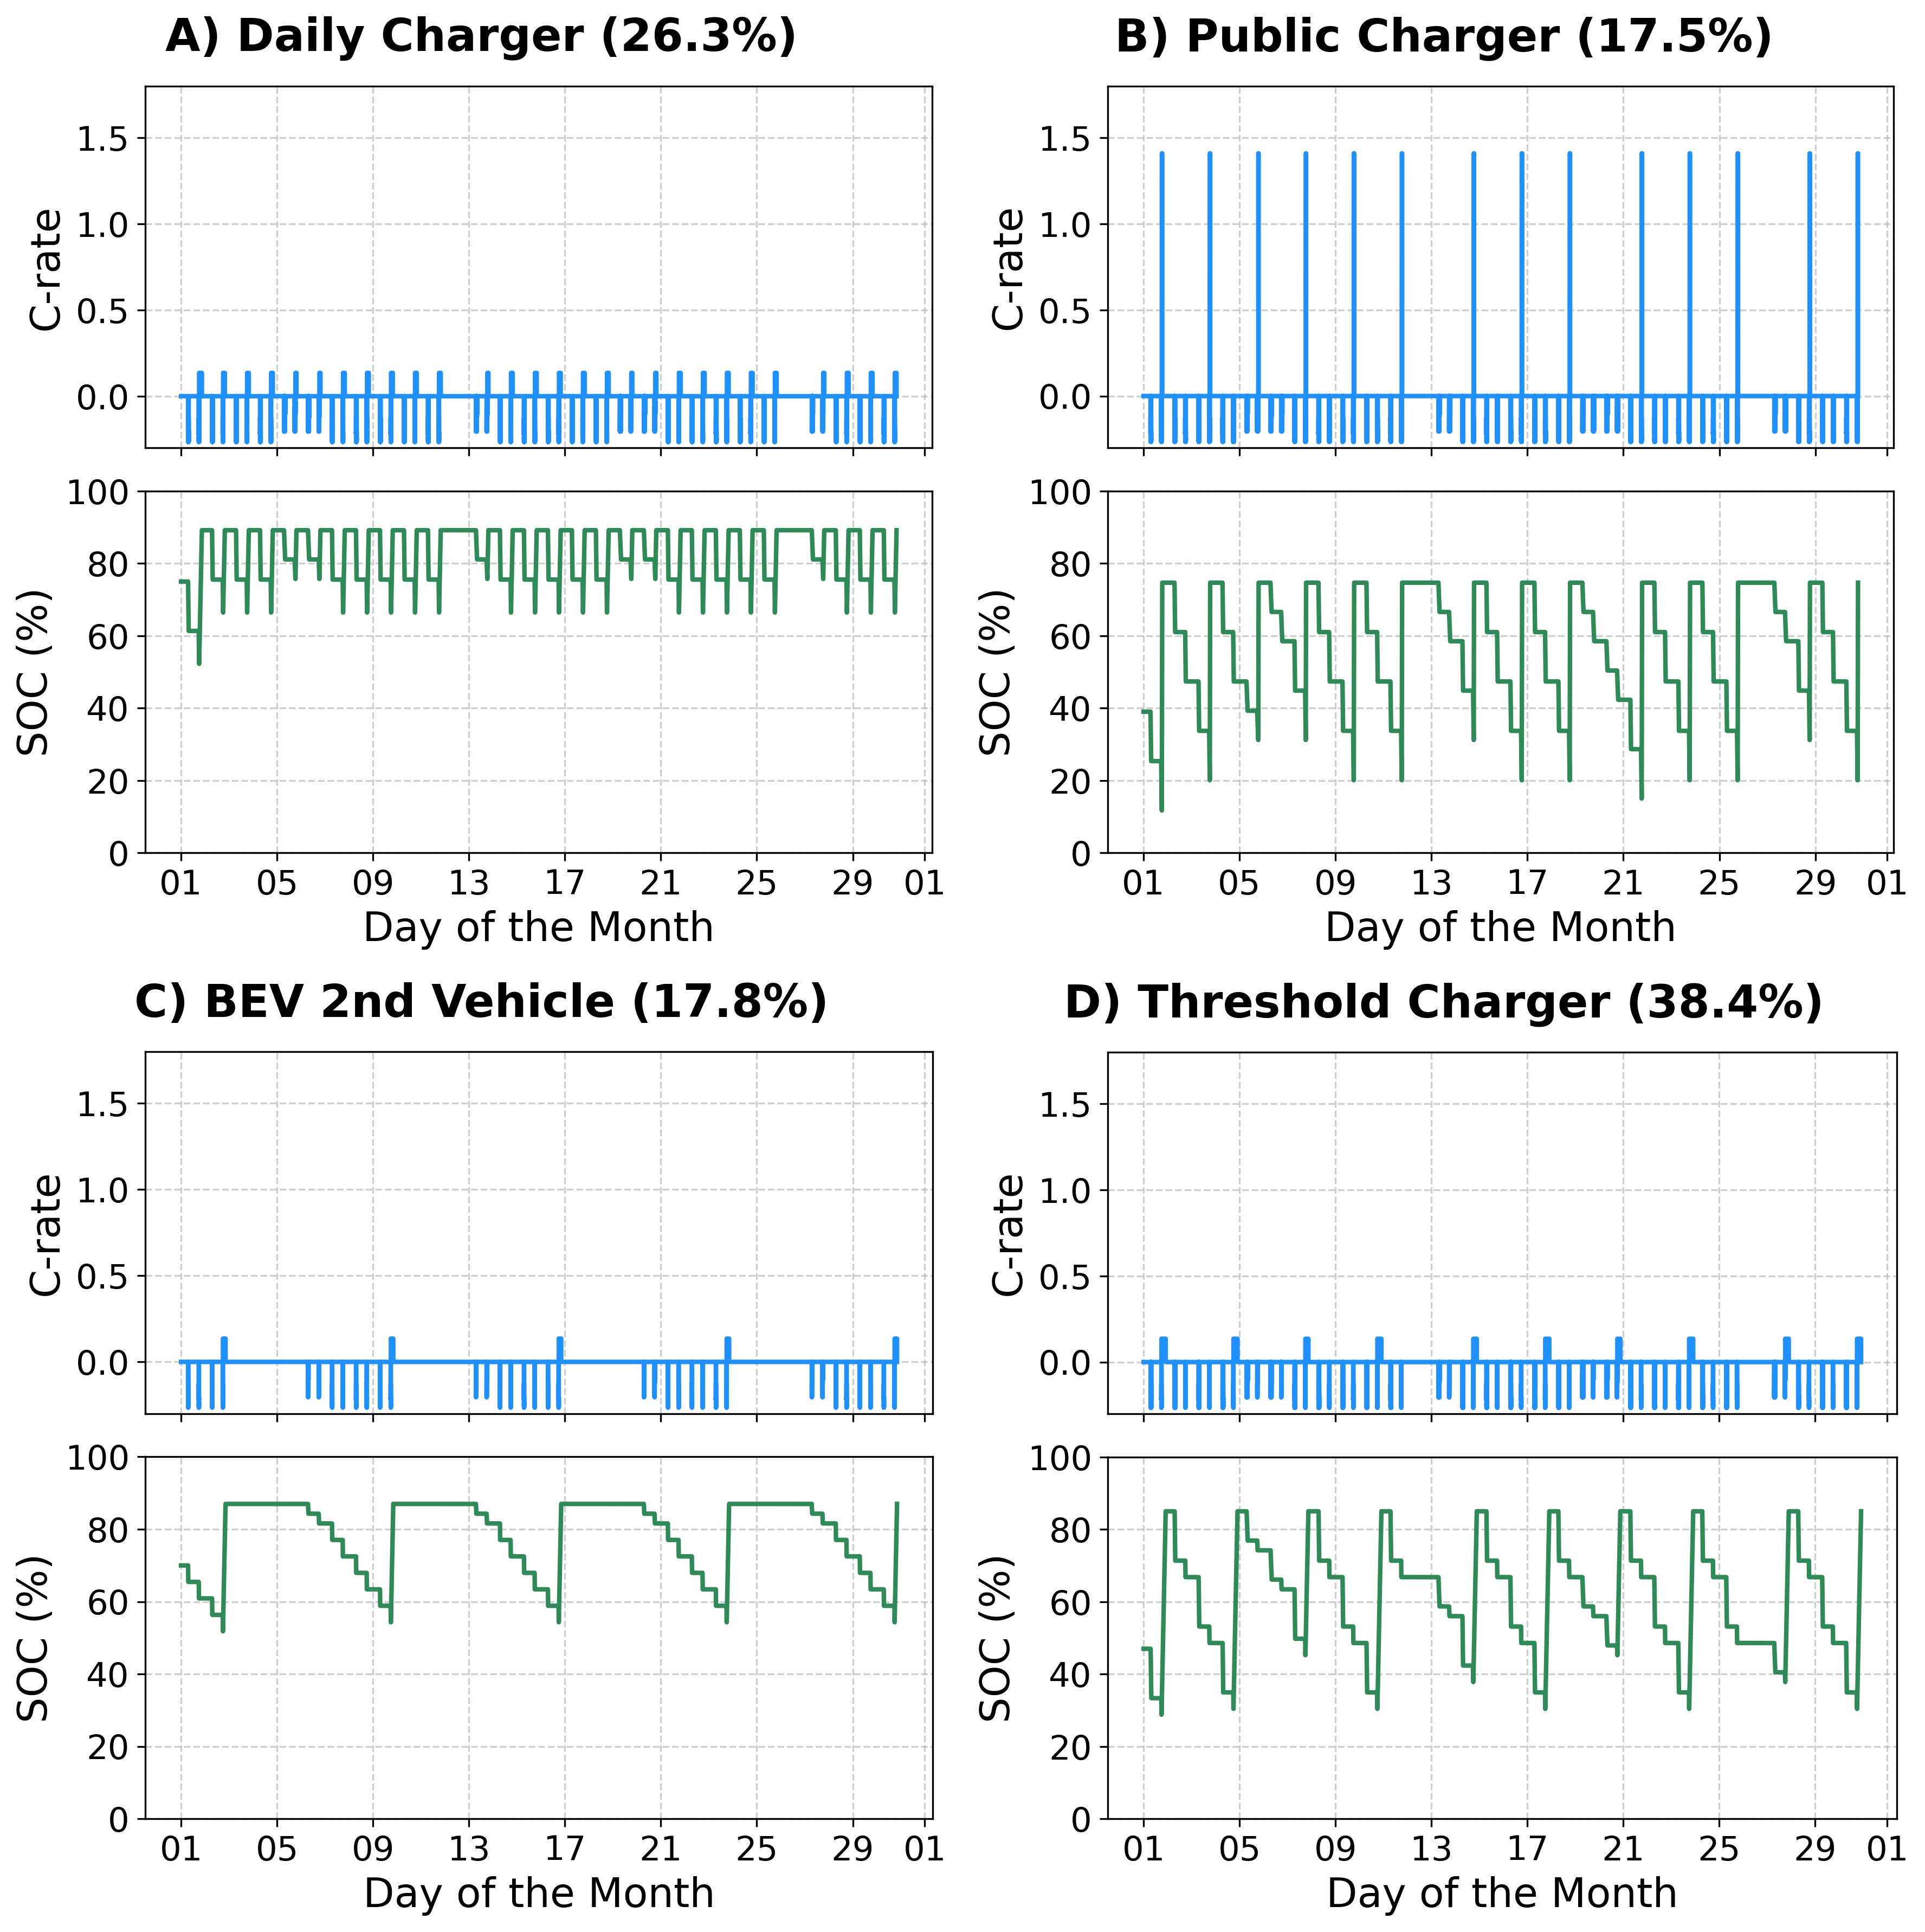

In [13]:
import io
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
behavior_figure_title ={
    'daily_charger': 'A) Daily Charger (26.3%)',
    'public_charger': 'B) Public Charger (17.5%)', 
    'bev_second_vehicle': 'C) BEV 2nd Vehicle (17.8%)', 
    'threshold_charger':'D) Threshold Charger (38.4%)'
}
data_dir = Path('../data/synthetic_vehicle_usage')
fig_dir = Path('../figures')
fig_dir.mkdir(parents=True, exist_ok=True)

# Render each behavior's figure to an in-memory image
images = []
for behavior in vehicle_usage_behavior_list:
    behavior_df = pd.read_parquet(data_dir / f'{behavior}.parquet')
    print(f"Generating plot for: {behavior}")
    fig = make_drive_cycle_figure_example_month(behavior_df, behavior_figure_title[behavior])

    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=300, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    buf.seek(0)
    images.append(Image.open(buf).convert('RGB'))

# Make every tile the same size (the largest), with white padding
tile_w = max(im.width for im in images)
tile_h = max(im.height for im in images)

grid = Image.new('RGB', (2 * tile_w, 2 * tile_h), 'white')
positions = [(0, 0), (tile_w, 0), (0, tile_h), (tile_w, tile_h)]  # UL, UR, LL, LR
for im, (x, y) in zip(images, positions):
    grid.paste(im, (x, y))

grid.save('../figures/Synthetic_driver_profiles.pdf', dpi=(300, 300))
grid  # displays the combined image in Jupyter

## Figure 1

In [5]:
def make_drive_cycle_comparison_figure_one_day ( drive_cycle_df_no_V2G , drive_cycle_df_V2G):
    
    fig, (ax_C_rate, ax_SOC) = plt.subplots(2, 1, figsize=(6, 6), sharex=True, dpi=300)

    # --- C-rate plot ---
    ax_C_rate.plot(drive_cycle_df_V2G['timestamp'], drive_cycle_df_V2G['C-rate'], 
                    color='dodgerblue', lw=2, alpha = .5, label ='With V2G')
    ax_C_rate.plot(drive_cycle_df_no_V2G['timestamp'], drive_cycle_df_no_V2G['C-rate'], 
                    color='dodgerblue', lw=2, label ='Without V2G')
    ax_C_rate.set_ylim([-0.3, 1.8])
    ax_C_rate.set_ylabel('C-rate', fontsize=24)
    ax_C_rate.grid(True, linestyle='--', alpha=0.6)

    # --- SOC plot ---
    ax_SOC.plot(drive_cycle_df_V2G['timestamp'], drive_cycle_df_V2G['SOC'] * 100, 
                color='seagreen', lw=2, alpha = .5, label ='With V2G')
    ax_SOC.plot(drive_cycle_df_no_V2G['timestamp'], drive_cycle_df_no_V2G['SOC'] * 100, 
                color='seagreen', lw=2, label ='Without V2G')

    ax_SOC.set_ylabel('SOC (%)', fontsize=24)
    ax_SOC.set_ylim([0, 101])
    ax_SOC.set_xlabel('Time', fontsize=24)
    ax_SOC.xaxis.set_major_formatter(mdates.DateFormatter('%-I\n%p'))
    ax_SOC.xaxis.set_major_locator(mdates.HourLocator(interval=3))
    start = dt.datetime(2024, 1, 2, 12, 0)   # Jan 1, 2024 at 12 AM
    end   = dt.datetime(2024, 1, 3, 12, 0)  # Jan 2, 2024 at 12 PM

    ax_SOC.set_xlim([start, end])

    ax_SOC.grid(True, linestyle='--', alpha=0.6)


    # --- Tick labels ---
    ax_C_rate.tick_params(axis='both', which='major', labelsize=16)
    ax_SOC.tick_params(axis='both', which='major', labelsize=16)

    ax_C_rate.legend(loc ='upper right')

    ax_SOC.legend(loc ='lower right')


    # Improve layout
    fig.tight_layout(pad=.4)


/Users/clementwong/Desktop/TRI Internship/v2g-journal-repo/src/v2g_strategy.py:224: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  new_session_start = is_plugged & ~(is_plugged.shift(1).fillna(False))


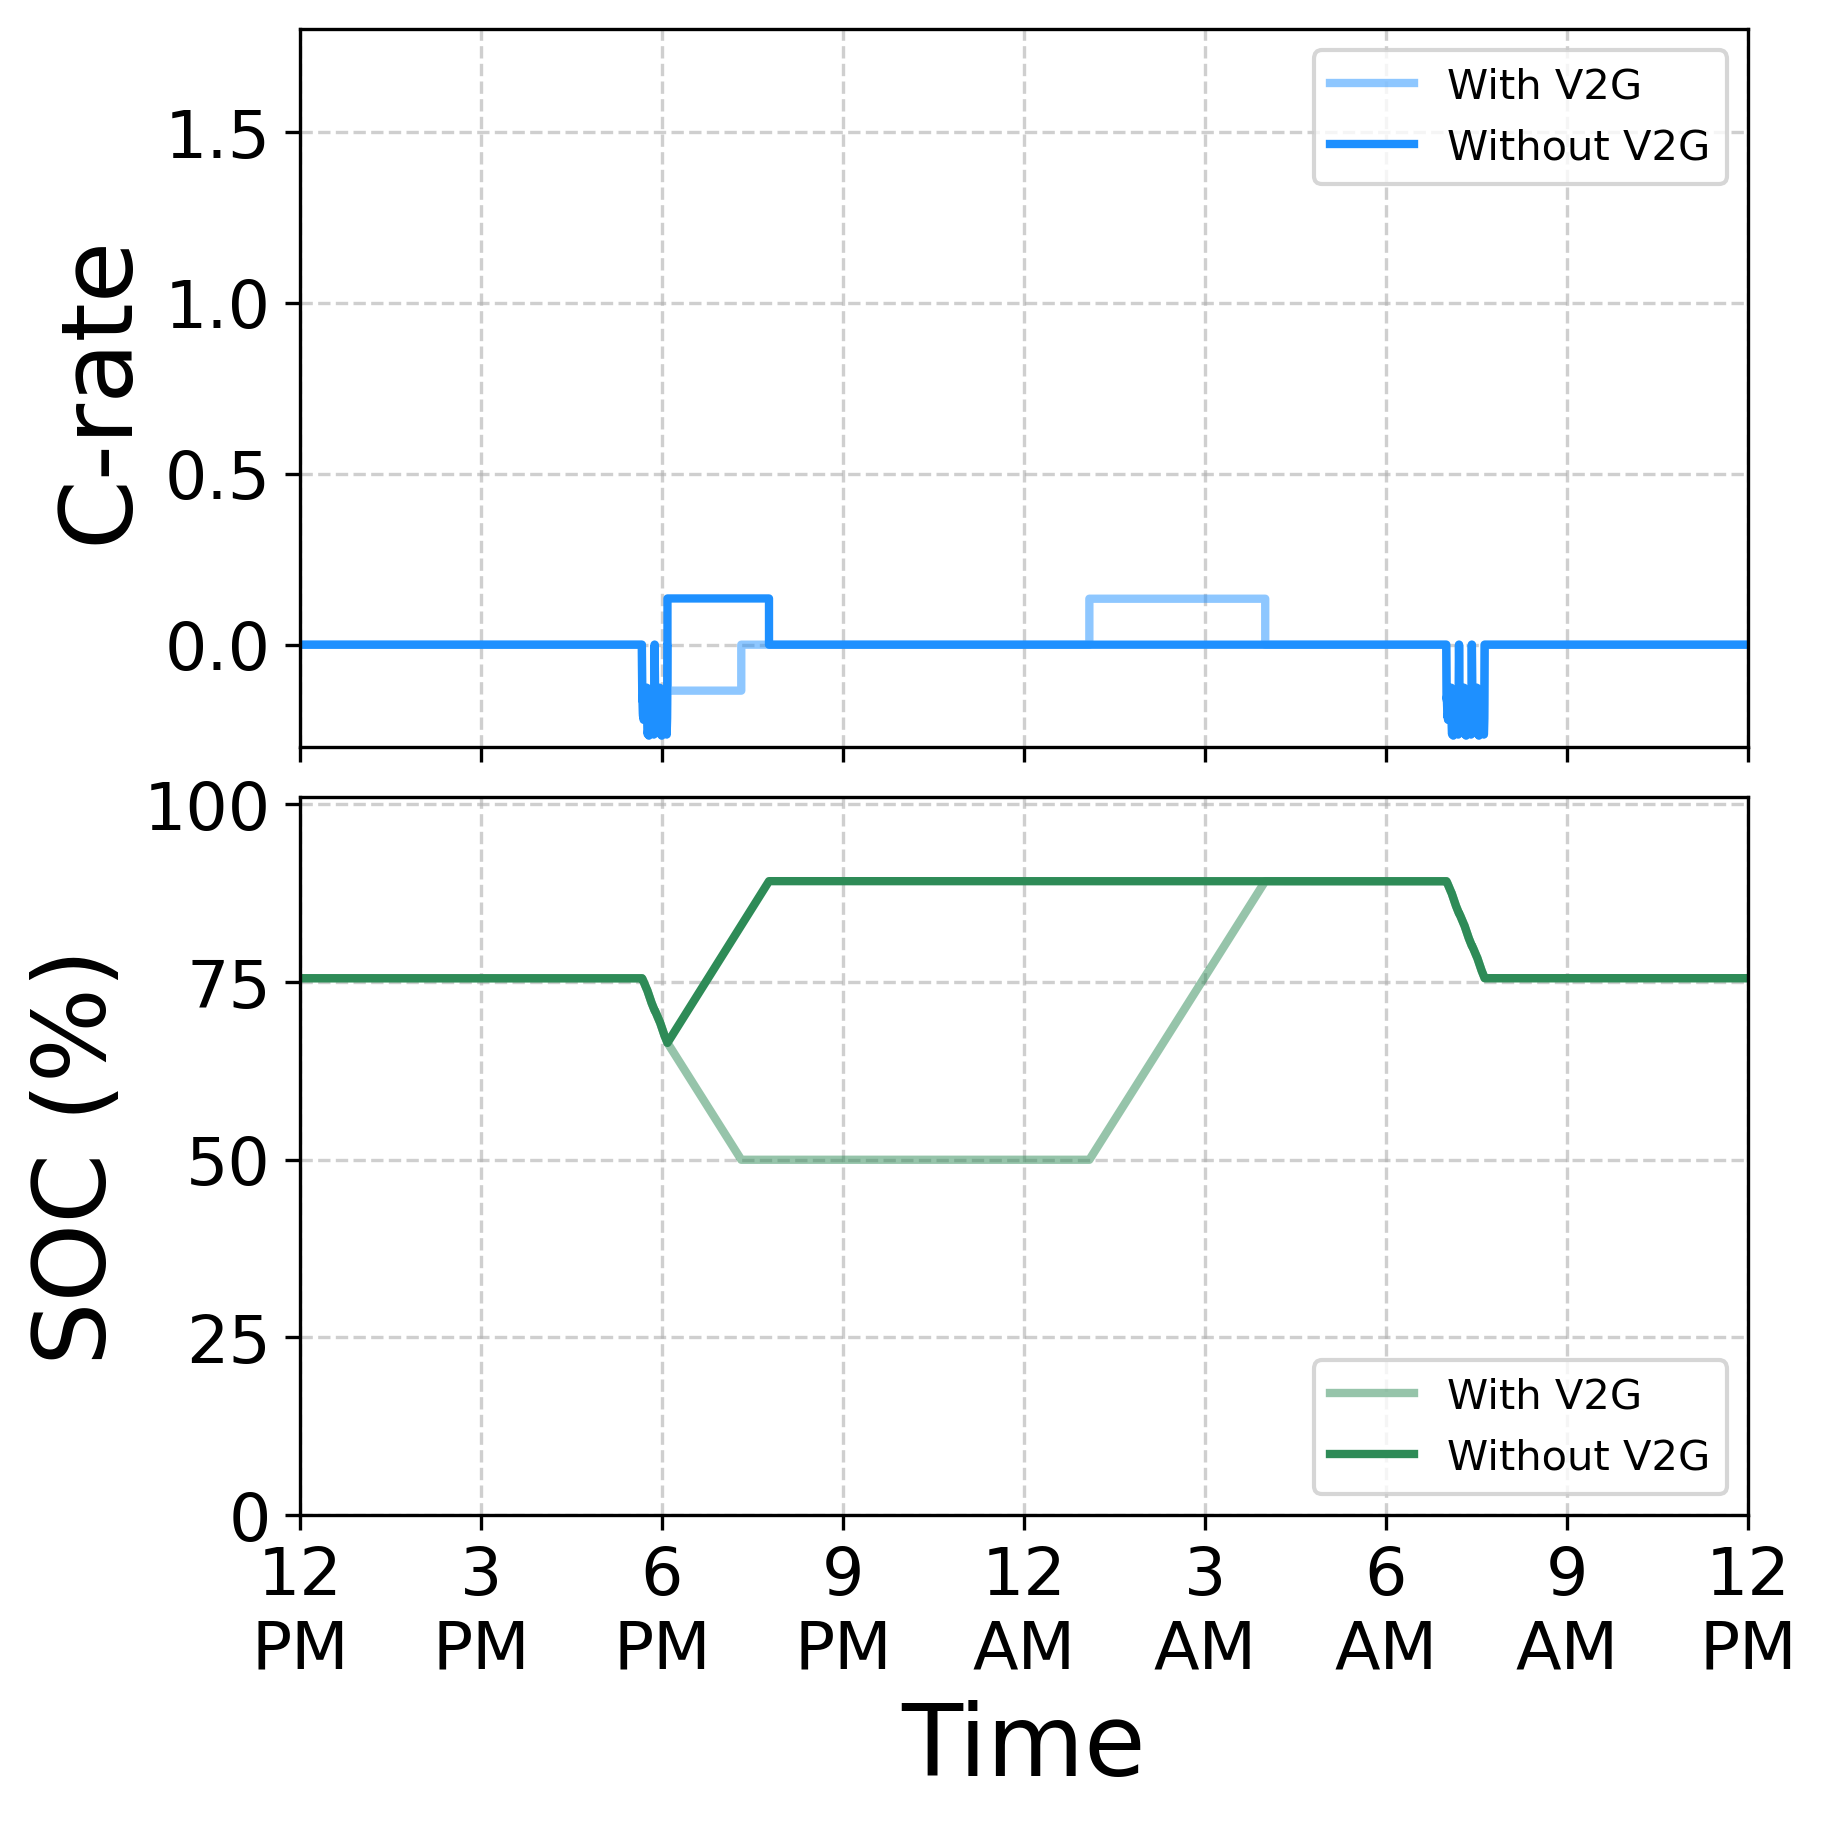

In [6]:
behavior = 'daily_charger'

# Load data
file_path = f'../data/synthetic_vehicle_usage/{behavior}.parquet'
behavior_df = pd.read_parquet(file_path)


# Take a week of drive cycle data and integrate V2G strategy
start_date = pd.Timestamp('2024-01-01')
end_date   = pd.Timestamp('2024-01-08')

drive_cycle_df_no_V2G = behavior_df[(behavior_df['timestamp'] >= start_date) &
                                    (behavior_df['timestamp'] < end_date)].copy()
drive_cycle_df_V2G  = integrate_v2g(drive_cycle_df_no_V2G)

make_drive_cycle_comparison_figure_one_day ( drive_cycle_df_no_V2G , drive_cycle_df_V2G)